In [0]:
import numpy as np
import pandas as pd

from pyspark.sql import functions as F

train_df = spark.table(
    "workspace.default.urban_mobility_train_features"
)

test_df = spark.table(
    "workspace.default.urban_mobility_test_features"
)

print("Training:", train_df.count())
print("Evaluation:", test_df.count())

Training: 95912
Evaluation: 24088


In [0]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

print("Required modelling libraries are available.")

Scikit-learn version: 1.7.2
Required modelling libraries are available.


In [0]:
for name, df in [
    ("Training", train_df),
    ("Evaluation", test_df)
]:
    print(f"\n{name} scenario distribution")

    display(
        df.groupBy("scenario_label")
          .count()
          .orderBy(F.desc("count"))
    )


Training scenario distribution


scenario_label,count
Routine,93421
Review,2491



Evaluation scenario distribution


scenario_label,count
Routine,23459
Review,629


In [0]:
feature_columns = [
    "trip_distance_km",
    "trip_duration_min",
    "average_speed_kmh",
    "total_amount_eur",
    "fare_per_km_eur",
    "tip_to_fare_ratio",
    "is_peak_period",
    "speed_deviation",
    "duration_deviation",
    "fare_per_km_deviation"
]

# Labels are retained separately for evaluation only.
train_pd = train_df.select(
    "trip_id", *feature_columns
).toPandas()

test_pd = test_df.select(
    "trip_id", *feature_columns,
    "scenario_label", "scenario_detail"
).toPandas()

X_train = train_pd[feature_columns]
X_test = test_pd[feature_columns]

print("Training shape:", X_train.shape)
print("Evaluation shape:", X_test.shape)
print("Missing values:", X_train.isna().sum().sum(),
      X_test.isna().sum().sum())

Training shape: (95912, 10)
Evaluation shape: (24088, 10)
Missing values: 0 0


In [0]:
context_columns = [
    "speed_deviation",
    "duration_deviation",
    "fare_per_km_deviation"
]

# Training-only robust scaling
medians = X_train[context_columns].median()

mad = (
    X_train[context_columns]
    .sub(medians)
    .abs()
    .median()
    .replace(0, 1e-6)
)

def rule_score(X):
    deviations = (
        X[context_columns]
        .sub(medians)
        .abs()
        .div(mad)
    )
    return deviations.max(axis=1).to_numpy()

train_rule_scores = rule_score(X_train)
test_rule_scores = rule_score(X_test)

print("Rule-based scores calculated.")

Rule-based scores calculated.


## Training isolation forest

In [0]:
from sklearn.ensemble import IsolationForest

model = IsolationForest(
    n_estimators=150,
    max_samples=256,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train)

# Higher scores indicate greater abnormality.
train_if_scores = -model.score_samples(X_train)
test_if_scores = -model.score_samples(X_test)

print("Isolation Forest training complete.")

Isolation Forest training complete.


In [0]:
alert_rate = 0.026

rule_threshold = np.quantile(
    train_rule_scores, 1 - alert_rate
)

if_threshold = np.quantile(
    train_if_scores, 1 - alert_rate
)

rule_predictions = (
    test_rule_scores > rule_threshold
).astype(int)

if_predictions = (
    test_if_scores > if_threshold
).astype(int)

print("Rule-based alerts:", rule_predictions.sum())
print("Isolation Forest alerts:", if_predictions.sum())

Rule-based alerts: 652
Isolation Forest alerts: 634


In [0]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

y_test = (
    test_pd["scenario_label"] == "Review"
).astype(int)

def evaluate_detector(name, predictions, scores):
    return {
        "Detector": name,
        "Alerts": int(predictions.sum()),
        "Precision": round(
            precision_score(y_test, predictions, zero_division=0), 4
        ),
        "Recall": round(
            recall_score(y_test, predictions, zero_division=0), 4
        ),
        "F1": round(
            f1_score(y_test, predictions, zero_division=0), 4
        ),
        "PR-AUC (AP)": round(
            average_precision_score(y_test, scores), 4
        )
    }

results_df = pd.DataFrame([
    evaluate_detector(
        "Contextual Rules",
        rule_predictions,
        test_rule_scores
    ),
    evaluate_detector(
        "Isolation Forest",
        if_predictions,
        test_if_scores
    )
])

display(results_df)

Detector,Alerts,Precision,Recall,F1,PR-AUC (AP)
Contextual Rules,652,0.4095,0.4245,0.4169,0.384
Isolation Forest,634,0.429,0.4324,0.4307,0.3326


In [0]:
# Reshape the model results for visualization

metrics_chart_df = (
    results_df
    .melt(
        id_vars="Detector",
        value_vars=[
            "Precision",
            "Recall",
            "F1",
            "PR-AUC (AP)"
        ],
        var_name="Metric",
        value_name="Score"
    )
)

# Convert scores to percentages
metrics_chart_df["Score (%)"] = (
    metrics_chart_df["Score"] * 100
).round(2)

display(metrics_chart_df)

Detector,Metric,Score,Score (%)
Contextual Rules,Precision,0.4095,40.95
Isolation Forest,Precision,0.429,42.9
Contextual Rules,Recall,0.4245,42.45
Isolation Forest,Recall,0.4324,43.24
Contextual Rules,F1,0.4169,41.69
Isolation Forest,F1,0.4307,43.07
Contextual Rules,PR-AUC (AP),0.384,38.4
Isolation Forest,PR-AUC (AP),0.3326,33.26


Databricks visualization. Run in Databricks to view.

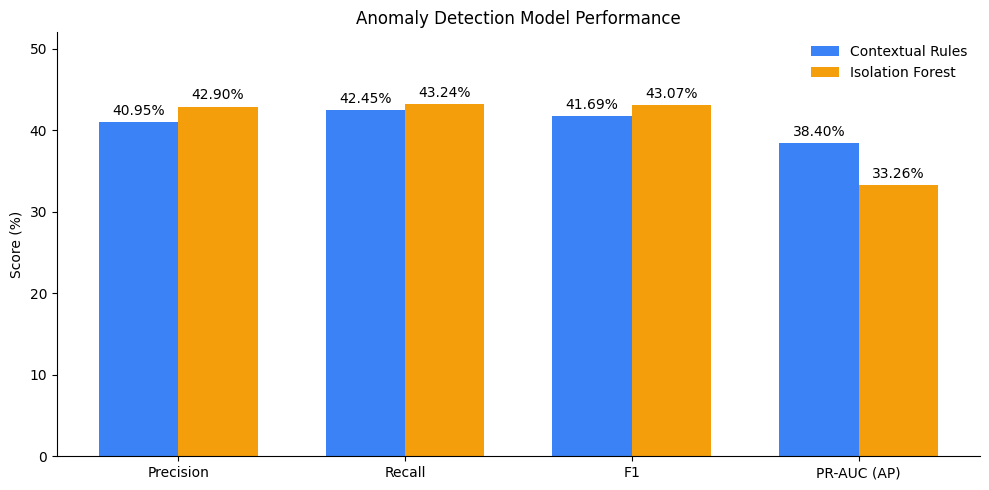

In [0]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Precision", "Recall", "F1", "PR-AUC (AP)"]

rules = (
    results_df
    .set_index("Detector")
    .loc["Contextual Rules", metrics]
    .astype(float)
    .to_numpy() * 100
)

forest = (
    results_df
    .set_index("Detector")
    .loc["Isolation Forest", metrics]
    .astype(float)
    .to_numpy() * 100
)

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

bars1 = ax.bar(
    x - width / 2,
    rules,
    width,
    label="Contextual Rules",
    color="#3B82F6"
)

bars2 = ax.bar(
    x + width / 2,
    forest,
    width,
    label="Isolation Forest",
    color="#F59E0B"
)

ax.bar_label(bars1, fmt="%.2f%%", padding=3)
ax.bar_label(bars2, fmt="%.2f%%", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 52)
ax.set_title("Anomaly Detection Model Performance")
ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "model_performance.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [0]:
# Attach model predictions to evaluation records
evaluation_pd = test_pd[
    ["trip_id", "scenario_label", "scenario_detail"]
].copy()

evaluation_pd["rule_alert"] = rule_predictions
evaluation_pd["if_alert"] = if_predictions

# Detection performance by injected scenario
scenario_results = (
    evaluation_pd[
        evaluation_pd["scenario_label"] == "Review"
    ]
    .groupby("scenario_detail")
    .agg(
        total_scenarios=("trip_id", "count"),
        rules_detected=("rule_alert", "sum"),
        if_detected=("if_alert", "sum")
    )
    .reset_index()
)

scenario_results["rules_recall_pct"] = (
    100 * scenario_results["rules_detected"]
    / scenario_results["total_scenarios"]
).round(2)

scenario_results["if_recall_pct"] = (
    100 * scenario_results["if_detected"]
    / scenario_results["total_scenarios"]
).round(2)

display(
    scenario_results.sort_values(
        "total_scenarios", ascending=False
    )
)

scenario_detail,total_scenarios,rules_detected,if_detected,rules_recall_pct,if_recall_pct
Fare-to-distance outlier,188,145,137,77.13,72.87
Duration-to-distance outlier,145,26,22,17.93,15.17
Distance-to-duration outlier,131,49,70,37.4,53.44
Very short trip duration,86,46,29,53.49,33.72
Tip-to-fare outlier,79,1,14,1.27,17.72


In [0]:
both = (
    (evaluation_pd["rule_alert"] == 1)
    & (evaluation_pd["if_alert"] == 1)
).sum()

rules_only = (
    (evaluation_pd["rule_alert"] == 1)
    & (evaluation_pd["if_alert"] == 0)
).sum()

if_only = (
    (evaluation_pd["rule_alert"] == 0)
    & (evaluation_pd["if_alert"] == 1)
).sum()

neither = (
    (evaluation_pd["rule_alert"] == 0)
    & (evaluation_pd["if_alert"] == 0)
).sum()

agreement_df = pd.DataFrame({
    "Detection category": [
        "Both detectors",
        "Rules only",
        "Isolation Forest only",
        "Neither"
    ],
    "Trips": [
        both, rules_only, if_only, neither
    ]
})

display(agreement_df)

Detection category,Trips
Both detectors,426
Rules only,226
Isolation Forest only,208
Neither,23228


In [0]:
# Combine the existing predictions
either_alert = (
    (rule_predictions == 1) |
    (if_predictions == 1)
).astype(int)

both_alert = (
    (rule_predictions == 1) &
    (if_predictions == 1)
).astype(int)

# Compare all four approaches
combined_results_df = pd.DataFrame([
    evaluate_detector(
        "Contextual Rules",
        rule_predictions,
        test_rule_scores
    ),
    evaluate_detector(
        "Isolation Forest",
        if_predictions,
        test_if_scores
    ),
    evaluate_detector(
        "Either Detector",
        either_alert,
        either_alert
    ),
    evaluate_detector(
        "Both Detectors",
        both_alert,
        both_alert
    )
])

display(
    combined_results_df[
        ["Detector", "Alerts", "Precision", "Recall", "F1"]
    ]
)

Detector,Alerts,Precision,Recall,F1
Contextual Rules,652,0.4095,0.4245,0.4169
Isolation Forest,634,0.429,0.4324,0.4307
Either Detector,860,0.3756,0.5135,0.4338
Both Detectors,426,0.507,0.3434,0.4095


Databricks visualization. Run in Databricks to view.

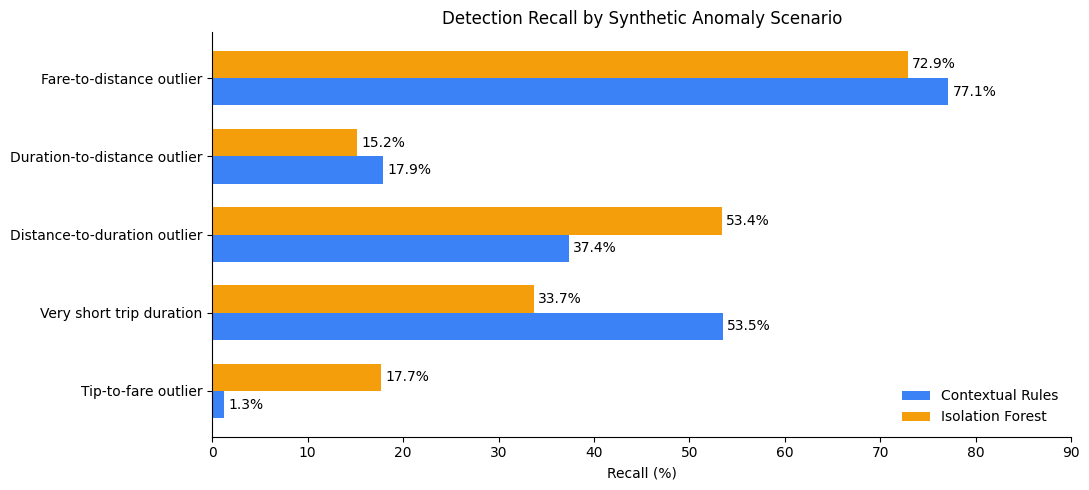

In [0]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = scenario_results.sort_values(
    "total_scenarios", ascending=True
)

y = np.arange(len(plot_df))
height = 0.35

fig, ax = plt.subplots(figsize=(11, 5))

bars1 = ax.barh(
    y - height / 2,
    plot_df["rules_recall_pct"],
    height,
    label="Contextual Rules",
    color="#3B82F6"
)

bars2 = ax.barh(
    y + height / 2,
    plot_df["if_recall_pct"],
    height,
    label="Isolation Forest",
    color="#F59E0B"
)

ax.bar_label(bars1, fmt="%.1f%%", padding=3)
ax.bar_label(bars2, fmt="%.1f%%", padding=3)

ax.set_yticks(y)
ax.set_yticklabels(plot_df["scenario_detail"])
ax.set_xlim(0, 90)
ax.set_xlabel("Recall (%)")
ax.set_title("Detection Recall by Synthetic Anomaly Scenario")
ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "scenario_recall.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


## Final Evaluation and Conclusions

### 1. Project Objective

This project investigated whether contextual trip and transaction features could identify unusual activity within a synthetic urban mobility dataset containing 120,000 journeys.

Two unsupervised anomaly detection approaches were evaluated:
- **Contextual Rules:** An interpretable baseline using deviations in speed, duration, and fare per kilometre.
- **Isolation Forest:** A machine learning model designed to identify unusual combinations of trip and transaction characteristics.

Both approaches were evaluated against held-out synthetic review scenarios using a chronological train/test split.

### 2. Model Performance

| Detector | Alerts | Precision | Recall | F1 |
|---|---:|---:|---:|---:|
| Contextual Rules | 652 | 40.95% | 42.45% | 41.69% |
| Isolation Forest | 634 | 42.90% | 43.24% | 43.07% |
| Either Detector | 860 | 37.56% | 51.35% | 43.38% |
| Both Detectors | 426 | 50.70% | 34.34% | 40.95% |

Isolation Forest achieved slightly higher precision, recall, and F1 than the contextual rule-based detector at the selected alert threshold.

However, Contextual Rules achieved higher average precision across thresholds (**0.3840 versus 0.3326**), indicating that the machine learning approach did not consistently outperform the simpler baseline.

### 3. Key Findings

**Contextual information improves anomaly assessment.**

Journey characteristics vary across operational periods. Using time-period-adjusted deviations provides a more meaningful basis for identifying unusual activity than relying exclusively on absolute transaction values.

**Detection effectiveness varies by anomaly type.**

Both detectors performed relatively well on fare-to-distance outliers but struggled with duration-to-distance and tip-to-fare anomalies. Isolation Forest performed better on distance-to-duration and tip-to-fare scenarios, while Contextual Rules performed better on very short trip durations.

**Combining detectors introduces operational trade-offs.**

Flagging trips identified by either detector increased recall to **51.35%**, but generated 860 alerts and reduced precision to 37.56%.

Requiring agreement between both detectors increased precision to **50.70%** and reduced alerts to 426, but lowered recall to 34.34%.

These results demonstrate the trade-off between detection coverage and review workload.

### 4. Limitations

- **Synthetic data:** The dataset represents simulated journeys rather than actual transportation or financial activity.
- **Synthetic labels:** Review scenarios are deliberately injected anomalies, not confirmed fraudulent transactions.
- **Evaluation design:** Results are based on a single chronological train/test split.
- **Alert threshold:** The approximately 2.6% alert budget was informed by the known synthetic scenario prevalence and does not represent a validated operational threshold.
- **Contextual features:** Time-period baselines do not fully account for route, distance, weather, or service-specific differences.
- **Model scope:** Isolation Forest was evaluated using a compact numerical feature set without extensive hyperparameter optimization.
- **Generalizability:** Performance on real-world transaction monitoring data cannot be inferred from these results.

### 5. Final Conclusion

The project demonstrates an end-to-end batch analytics workflow combining **Databricks, PySpark, Delta Lake, contextual feature engineering, and unsupervised anomaly detection**.

The findings show that more complex models do not necessarily outperform interpretable baselines across every evaluation metric. Detection effectiveness also depends on the type of unusual behaviour being investigated and the number of alerts an organization can reasonably review.

Rather than identifying a universally superior detector, the project highlights the importance of **contextual analysis, transparent evaluation, and balancing precision, recall, and operational workload** when designing anomaly detection systems.
